In [1]:
from pathlib import Path
from scipy.io import whosmat

folders = [
    Path("data/raw/capacitor/12. Capacitor Electrical Stress"),
    Path("../data/raw/capacitor/12. Capacitor Electrical Stress"),
]
data_folder = next((p for p in folders if p.exists()), None)

if data_folder is None:
    raise FileNotFoundError("Can't find the capacitor data folder.")

print(whosmat(str(data_folder / "ES10.mat")))

NotImplementedError: Please use HDF reader for matlab v7.3 files, e.g. h5py

In [2]:
%pip install h5py

   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   --------- ------------------------------ 0.8/3.2 MB 3.9 MB/s eta 0:00:01
   ------------------- -------------------- 1.6/3.2 MB 3.7 MB/s eta 0:00:01
   -------------------------- ------------- 2.1/3.2 MB 3.4 MB/s eta 0:00:01
   ------------------------------------ --- 2.9/3.2 MB 3.3 MB/s eta 0:00:01
   ---------------------------------------- 3.2/3.2 MB 3.1 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


In [34]:
from pathlib import Path
import h5py

folders = [
    Path("data/raw/capacitor/12. Capacitor Electrical Stress"),
    Path("../data/raw/capacitor/12. Capacitor Electrical Stress"),
]
data_folder = next((p for p in folders if p.exists()), None)

if data_folder is None:
    raise FileNotFoundError("Can't find the capacitor data folder.")

with h5py.File(data_folder / "ES12.mat", "r") as f:
    print("Top-level entries:", list(f.keys()))
    for name, item in f.items():
        print(name, type(item).__name__, getattr(item, "shape", "group"))

Top-level entries: ['#refs#', 'ES12']
#refs# Group group
ES12 Group group


In [35]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    def describe(name, item):
        if isinstance(item, h5py.Dataset):
            print(f"DATASET {name}: shape={item.shape}, type={item.dtype}")
        else:
            print(f"GROUP {name}")

    f["ES12"].visititems(describe)

GROUP EIS_Data
DATASET EIS_Data/EIS_Reference_Table: shape=(4, 73), type=object
GROUP EIS_Data/ES12C1
GROUP EIS_Data/ES12C1/EIS_Measurement
DATASET EIS_Data/ES12C1/EIS_Measurement/ColumNames: shape=(73, 1), type=object
DATASET EIS_Data/ES12C1/EIS_Measurement/Data: shape=(73, 1), type=object
DATASET EIS_Data/ES12C1/EIS_Measurement/Header: shape=(73, 1), type=object
GROUP EIS_Data/ES12C2
GROUP EIS_Data/ES12C2/EIS_Measurement
DATASET EIS_Data/ES12C2/EIS_Measurement/ColumNames: shape=(73, 1), type=object
DATASET EIS_Data/ES12C2/EIS_Measurement/Data: shape=(73, 1), type=object
DATASET EIS_Data/ES12C2/EIS_Measurement/Header: shape=(73, 1), type=object
GROUP EIS_Data/ES12C3
GROUP EIS_Data/ES12C3/EIS_Measurement
DATASET EIS_Data/ES12C3/EIS_Measurement/ColumNames: shape=(73, 1), type=object
DATASET EIS_Data/ES12C3/EIS_Measurement/Data: shape=(73, 1), type=object
DATASET EIS_Data/ES12C3/EIS_Measurement/Header: shape=(73, 1), type=object
GROUP EIS_Data/ES12C4
GROUP EIS_Data/ES12C4/EIS_Measurement

In [3]:
with h5py.File(data_folder / "ES10.mat", "r") as f:
    measurement = f["ES10"]["EIS_Data"]["ES10C1"]["EIS_Measurement"]

    for field in ["ColumnNames", "Header", "Data"]:
        cell = measurement[field]
        first_item = f[cell[0, 0]]
        print(field, "shape:", first_item.shape, "type:", first_item.dtype)
    

KeyError: "Unable to synchronously open object (object 'ColumnNames' doesn't exist)"

In [4]:
with h5py.File(data_folder / "ES10.mat", "r") as f:
    measurement = f["ES10"]["EIS_Data"]["ES10C1"]["EIS_Measurement"]

    for field in ["ColumnNames", "Header", "Data"]:
        item = measurement[field]
        sample = item[0, 0]
        print(field, "dtype:", item.dtype,
              "sample type:", type(sample).__name__,
              "sample:", repr(sample))

KeyError: "Unable to synchronously open object (object 'ColumnNames' doesn't exist)"

In [45]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    print("ES12 groups:", list(f["ES12"].keys()))
    print("EIS groups:", list(f["ES12"]["EIS_Data"].keys()))

    c1 = f["ES12"]["EIS_Data"]["ES12C1"]
    print("ES12C1 groups:", list(c1.keys()))
    print("Measurement entries:", list(c1["EIS_Measurement"].keys()))

ES12 groups: ['EIS_Data', 'Initial_Date', 'Transient_Data']
EIS groups: ['EIS_Reference_Table', 'ES12C1', 'ES12C2', 'ES12C3', 'ES12C4', 'ES12C5', 'ES12C6', 'ES12C7', 'ES12C8']
ES12C1 groups: ['EIS_Measurement']
Measurement entries: ['ColumNames', 'Data', 'Header']


In [6]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    measurement = f["ES12"]["EIS_Data"]["ES12C1"]["EIS_Measurement"]
    item = measurement["ColumnNames"]
    sample = item[0, 0]

    print("Shape:", item.shape)
    print("Stored value type:", type(sample).__name__)
    print("Stored value:", repr(sample))

KeyError: "Unable to synchronously open object (object 'ColumnNames' doesn't exist)"

In [39]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    measurement = f["ES12"]["EIS_Data"]["ES12C1"]["EIS_Measurement"]

    for name in measurement.keys():
        link = measurement.get(name, getlink=True)
        print(name, type(link).__name__, repr(link))

ColumNames HardLink <h5py._hl.group.HardLink object at 0x00000289182F6270>
Data HardLink <h5py._hl.group.HardLink object at 0x000002897D6539D0>
Header HardLink <h5py._hl.group.HardLink object at 0x00000289182DDD10>


In [40]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    def inspect(name, item):
        if name == "EIS_Data/ES12C1/EIS_Measurement/ColumnNames":
            sample = item[0, 0]
            print("Shape:", item.shape)
            print("Type:", item.dtype)
            print("First value:", type(sample).__name__, repr(sample))

    f["ES12"].visititems(inspect)

In [41]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    def show(name, item):
        if "ColumnNames" in name:
            print(repr(name), type(item).__name__)

    f["ES12"].visititems(show)

In [15]:
%pip install mat73

Note: you may need to restart the kernel to use updated packages.


In [42]:
import mat73

es10_c1 = mat73.loadmat(
    str(data_folder / "ES12.mat"),
    only_include="ES12/EIS_Data/ES12C1"
)

print("Loaded top-level entries:", es12_c1.keys())

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\AppData\Local\Temp\ipykernel_31828\785873818.py", line 3, in <module>
    es10_c1 = mat73.loadmat(
        str(data_folder / "ES12.mat"),
        only_include="ES12/EIS_Data/ES12C1"
    )
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 347, in loadmat
    dictionary = decoder.mat2dict(hdf5)
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 93, in mat2dict
    d[var] = self.unpack_mat(hdf5[var])
             ~~~~~~~~~~~~~~~^^^^^^^^^^^
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 159, in unpack_mat
    unpacked = self.unpack_mat(elem, depth=dept

In [43]:
from pathlib import Path
import mat73

folders = [
    Path("data/raw/capacitor/12. Capacitor Electrical Stress"),
    Path("../data/raw/capacitor/12. Capacitor Electrical Stress"),
]
data_folder = next((p for p in folders if p.exists()), None)

if data_folder is None:
    raise FileNotFoundError("Can't find the capacitor data folder.")

reference = mat73.loadmat(
    str(data_folder / "ES12.mat"),
    only_include="ES12/EIS_Data/EIS_Reference_Table",
)
print("Loaded entries:", reference.keys())

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\AppData\Local\Temp\ipykernel_31828\2714977228.py", line 13, in <module>
    reference = mat73.loadmat(
        str(data_folder / "ES12.mat"),
        only_include="ES12/EIS_Data/EIS_Reference_Table",
    )
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 347, in loadmat
    dictionary = decoder.mat2dict(hdf5)
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 93, in mat2dict
    d[var] = self.unpack_mat(hdf5[var])
             ~~~~~~~~~~~~~~~^^^^^^^^^^^
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 159, in unpack_mat
    unpacked = self.unpack_ma

In [ ]:
import numpy as np

table = reference["ES12"]["EIS_Data"]["EIS_Reference_Table"]
print("Shape:", np.asarray(table).shape)
print("Sample:", repr(table)[:1500])

In [44]:
es = reference["ES12"]
print("ES12 type:", type(es))
print("ES12 preview:", repr(es)[:500])

KeyError: 'ES12'

In [5]:
import pandas as pd

rows = es["EIS_Data"]
table_df = pd.DataFrame([row["EIS_Reference_Table"] for row in rows])

print("Table shape:", table_df.shape)
display(table_df.head())

Table shape: (73, 4)


,0,1,2,3
0,9/29/2014,,,0
1,9/30/2014,,,0
2,10/1/2014,10:00 AM,12:00 PM,2
3,10/2/2014,4:00 PM,1:00 PM,23
4,10/3/2014,4:00 PM,7:20 AM,38.3333


In [6]:
display(table_df.to_string())

'             0         1         2        3\n0    9/29/2014                            0\n1    9/30/2014                            0\n2    10/1/2014  10:00 AM  12:00 PM        2\n3    10/2/2014   4:00 PM   1:00 PM       23\n4    10/3/2014   4:00 PM   7:20 AM  38.3333\n5    10/3/2014  10:20 AM  12:00 PM       40\n6    10/6/2014   2:25 PM   7:25 AM      105\n7    10/6/2014   9:40 AM  12:40 PM      108\n8    10/7/2014   2:55 PM   7:55 AM      125\n9    10/7/2014   9:45 AM  12:45 PM      128\n10   10/8/2014   3:00 PM   9:00 AM      146\n11   10/9/2014  11:30 AM   7:30 AM      166\n12  10/10/2014   9:40 AM   7:40 AM      188\n13  10/10/2014  10:15 AM   2:15 PM      192\n14  10/13/2014   4:25 PM  11:25 AM      259\n15  10/14/2014   1:45 PM   7:45 AM      277\n16  10/14/2014  10:30 AM  12:30 PM      279\n17  10/15/2014   2:50 PM   8:30 AM   296.66\n18  10/16/2014  10:40 AM   7:00 AM      317\n19  10/17/2014  10:00 AM   9:00 AM      352\n20  10/17/2014  11:30 AM   2:30 PM      355\n21  10/20

In [7]:
table_df.columns = ["date", "start_time", "end_time", "elapsed_hours"]
display(table_df.head(10))

,date,start_time,end_time,elapsed_hours
0,9/29/2014,,,0
1,9/30/2014,,,0
2,10/1/2014,10:00 AM,12:00 PM,2
3,10/2/2014,4:00 PM,1:00 PM,23
4,10/3/2014,4:00 PM,7:20 AM,38.3333
5,10/3/2014,10:20 AM,12:00 PM,40
6,10/6/2014,2:25 PM,7:25 AM,105
7,10/6/2014,9:40 AM,12:40 PM,108
8,10/7/2014,2:55 PM,7:55 AM,125
9,10/7/2014,9:45 AM,12:45 PM,128


In [8]:
c1_data = mat73.loadmat(
    str(data_folder / "ES10.mat"),
    only_include="ES10/EIS_Data/ES10C1/EIS_Measurement/Data",
)

print(repr(c1_data)[:1500])

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\AppData\Local\Temp\ipykernel_31828\2733148530.py", line 1, in <module>
    c1_data = mat73.loadmat(
        str(data_folder / "ES10.mat"),
        only_include="ES10/EIS_Data/ES10C1/EIS_Measurement/Data",
    )
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 347, in loadmat
    dictionary = decoder.mat2dict(hdf5)
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 93, in mat2dict
    d[var] = self.unpack_mat(hdf5[var])
             ~~~~~~~~~~~~~~~^^^^^^^^^^^
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\mat73\core.py", line 159, in unpack_mat
    unpacked = self.unpa

In [9]:
import h5py

mat_path = data_folder / "ES10.mat"

with h5py.File(mat_path, "r") as f:
    data_cells = f["ES10/EIS_Data/ES10C1/EIS_Measurement/Data"]
    print("Cells:", data_cells.shape)

    first_ref = data_cells[0, 0]
    first_measurement = f[first_ref]

    print("First measurement shape:", first_measurement.shape)
    print("First measurement sample:")
    print(first_measurement[:10])

Cells: (73, 1)
First measurement shape: (20, 1)
First measurement sample:
[[<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]]


In [10]:
import h5py

with h5py.File(mat_path, "r") as f:
    data_cells = f["ES10/EIS_Data/ES10C1/EIS_Measurement/Data"]
    first_measurement = f[data_cells[0, 0]]

    for i in range(3):
        value = f[first_measurement[i, 0]]
        print(f"Item {i}: shape={value.shape}, dtype={value.dtype}")
        print(value[()])

Item 0: shape=(18, 59), dtype=float64
[[  0.           0.           0.         ... 131.899292   114.742943
  100.032005  ]
 [  0.           0.           0.         ...   0.24319415   0.24736586
    0.2504265 ]
 [  0.           0.           0.         ...   0.61732847   0.70574641
    0.80548096]
 ...
 [  0.           0.           0.         ...   1.40226126   1.26191127
    1.1320678 ]
 [  0.           0.           0.         ...   1.50714946   1.33718061
    1.18551922]
 [  0.           0.           0.         ...  68.49823     70.6843109
   72.7293701 ]]
Item 1: shape=(18, 59), dtype=float64
[[  0.           0.           0.         ... 131.899292   114.742943
  100.032005  ]
 [  0.           0.           0.         ...   0.24375781   0.24603739
    0.24997775]
 [  0.           0.           0.         ...   0.61686051   0.7050941
    0.80496561]
 ...
 [  0.           0.           0.         ...   1.40216362   1.26430714
    1.13302267]
 [  0.           0.           0.         ...   1.

In [11]:
with h5py.File(mat_path, "r") as f:
    measurement = f["ES10/EIS_Data/ES10C1/EIS_Measurement"]

    for field in ["ColumnNames", "Header"]:
        first_ref = measurement[field][0, 0]
        item = f[first_ref]
        print(field, "shape:", item.shape, "type:", item.dtype)
        print(item[()])

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\AppData\Local\Temp\ipykernel_31828\249049966.py", line 5, in <module>
    first_ref = measurement[field][0, 0]
                ~~~~~~~~~~~^^^^^^^
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\h5py\_hl\group.py", line 407, in __getitem__
    return self._get(name)
           ~~~~~~~~~^^^^^^
  File "h5py/_objects.pyx", line 54, in h5py._objects.with_phil.wrapper
  File "h5py/_objects.pyx", line 55, in h5py._objects.with_phil.wrapper
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\h5py\_hl\group.py", line 421, in _get
    oid = h5o.open(self.id, self._e(name), lapl=lapl)
  File "h5py/_objects.pyx", line 54, in h5py._objects.with_phil.w

In [12]:
with h5py.File(mat_path, "r") as f:
    measurement = f["ES10/EIS_Data/ES10C1/EIS_Measurement"]
    found = {}

    def collect(name, item):
        if name in ["ColumnNames", "Header"]:
            found[name] = item

    measurement.visititems(collect)

    print("Found:", list(found.keys()))
    for name, item in found.items():
        print(name, "shape:", item.shape, "type:", item.dtype)

Found: ['Header']
Header shape: (73, 1) type: object


In [14]:
with h5py.File(mat_path, "r") as f:
    measurement = f["ES10/EIS_Data/ES10C1/EIS_Measurement"]
    header_cells = measurement["Header"]
    first_header = f[header_cells[0, 0]]

    print("Shape:", first_header.shape)
    print("Type:", first_header.dtype)
    print(first_header[()])

Shape: (20, 1)
Type: object
[[<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]
 [<HDF5 object reference>]]


In [15]:
with h5py.File(mat_path, "r") as f:
    measurement = f["ES10/EIS_Data/ES10C1/EIS_Measurement"]
    header_cells = measurement["Header"]
    first_header = f[header_cells[0, 0]]

    for i in range(5):
        item = f[first_header[i, 0]]
        print(f"Header item {i}: shape={item.shape}, type={item.dtype}")
        print(item[()])

Header item 0: shape=(89, 54), type=uint16
[[ 69  78  80 ... 103 110 105]
 [ 67  98 111 ... 111 114 110]
 [ 45  32 116 ... 116  32  99]
 ...
 [ 32  32  32 ...  32  32  32]
 [ 32  32  32 ...  32  32  32]
 [ 32  32  32 ...  32  32  32]]
Header item 1: shape=(89, 54), type=uint16
[[ 69  78  80 ... 103 110 105]
 [ 67  98 111 ... 111 114 110]
 [ 45  32 116 ... 116  32  99]
 ...
 [ 32  32  32 ...  32  32  32]
 [ 32  32  32 ...  32  32  32]
 [ 32  32  32 ...  32  32  32]]
Header item 2: shape=(89, 54), type=uint16
[[ 69  78  80 ... 103 110 105]
 [ 67  98 111 ... 111 114 110]
 [ 45  32 116 ... 116  32  99]
 ...
 [ 32  32  32 ...  32  32  32]
 [ 32  32  32 ...  32  32  32]
 [ 32  32  32 ...  32  32  32]]
Header item 3: shape=(89, 54), type=uint16
[[ 69  78  80 ... 103 110 105]
 [ 67  98 111 ... 111 114 110]
 [ 45  32 116 ... 116  32  99]
 ...
 [ 32  32  32 ...  32  32  32]
 [ 32  32  32 ...  32  32  32]
 [ 32  32  32 ...  32  32  32]]
Header item 4: shape=(89, 54), type=uint16
[[ 69  78  80 ...

In [16]:
with h5py.File(mat_path, "r") as f:
    measurement = f["ES10/EIS_Data/ES10C1/EIS_Measurement"]
    first_header = f[measurement["Header"][0, 0]]
    header_array = first_header[()]

    lines = [
        "".join(chr(int(code)) for code in row).rstrip()
        for row in header_array
    ]

    print("\n".join(lines[:20]))

TypeError: int() argument must be a string, a bytes-like object or a real number, not 'h5py.h5r.Reference'

In [17]:
with h5py.File(mat_path, "r") as f:
    measurement = f["ES10/EIS_Data/ES10C1/EIS_Measurement"]
    header_refs = f[measurement["Header"][0, 0]]
    text_array = f[header_refs[0, 0]][()]

    lines = [
        "".join(chr(int(code)) for code in row).rstrip()
        for row in text_array
    ]

    print("\n".join(lines[:20]))

ENPRUCEEAS			DAEICEIECECEDMEvtrdudfufuSNNLVpNEEIBcngni
CbousElwcaFDHedCnolnlolhqeu sEeIntinfnedtoawa   aocorn
- tne eeqviiovd-tmeiemeaunl(. c i  i il  g   rrRnr t c
Lhe rvc uelrsirLemctcmcristV (o t( t t    (  aaadrcoc.
aeno stcideetcearatitetavii) hr  s    N   m  nnnw y y
batn:.rts  c esbnnrarnrcat   :d d) f fd   V  gggi cNcc
 di   orio:t: s edolototlyS  m  I  i f    )  eeed lsly
AeocjWdltn o : ft d lsdee i  :                  t e'ec
Sr haEe i Tr1 :o iesy ern:n  s               mm h s sl
C Eas  ro:ey2S rsn tt: it e  )               ia      e
Illnoccan s 7PU etmae ss 0                   nx
Iiennoon  t:.-Swreat  utW.
 nce mngs   01Bivrte: rie0                   ((
Fetl pnet 1C.5 nepe   fci0                   VV
Isr  le a 0:00 drrr:  a g0                   ))
L o: ic:r _\.  o ei   cmh
E:c  at t CU1( wvta   eatg
  h1 nime 0s S s1ol    s /
 5e  coid 1e N  0r    as:c
 8m( enn  .r   v. :   r  m


In [18]:
lines = [
    "".join(chr(int(code)) for code in row).rstrip()
    for row in text_array.T
]

print("\n".join(lines[:20]))

EC-Lab ASCII FILE
Nb header lines : 58
Potentio Electrochemical Impedance Spectroscopy
Run on channel : 1 (SN 3864)
User : jason
CE vs. WE compliance from -10 V to 10 V
Electrode connection : standard
Ewe ctrl range : min = -10.00 V, max = 10.00 V
Acquisition started on : 09/29/2014 11:21:40
Saved on :
	File : Test 10_C01.mpr
	Directory : C:\Users\pcoe3user\Documents\Capacitor Characteristics\09-26-14\ES10\Cap #1\
	Host : 127.0.0.1
Device : SP-150 (SN 0020)
Address : USB
EC-Lab for windows v10.39 (software)
Internet server v10.38 (firmware)
Command interpretor v10.38 (firmware)
Electrode material :
Initial state :


In [19]:
print("\n".join(lines[20:]))

Electrolyte :
Comments :
Electrode surface area : 0.001 cm²
Characteristic mass : 0.001 g
Equivalent Weight : 0.000 g/eq.
Density : 0.000 g/cm3
Multi Sine          0
E (V)               0.0000
vs.                 Ref
tE (h:m:s)          0:00:1.0000
record              1
dI                  1.000
unit dI             mA
dt (s)              0.100
fi                  100.000
unit fi             kHz
ff                  100.000
unit ff             Hz
Sel Nd              0
Nd                  6
Nt                  51
Log                 1
Va (mV)             10.0
pw                  0.10
Na                  1
E range min (V)     -10.000
E range max (V)     10.000
I Range             Auto
Bandwidth           5
corr                1
nc cycles           0
goto Ns'            0
nr cycles           0
inc. cycle          0


In [20]:
print("\n".join(lines[-15:]))

Nd                  6
Nt                  51
Log                 1
Va (mV)             10.0
pw                  0.10
Na                  1
E range min (V)     -10.000
E range max (V)     10.000
I Range             Auto
Bandwidth           5
corr                1
nc cycles           0
goto Ns'            0
nr cycles           0
inc. cycle          0


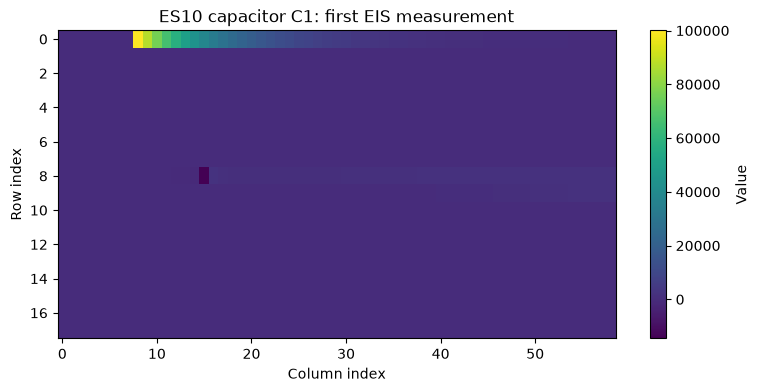

In [21]:
import matplotlib.pyplot as plt

with h5py.File(mat_path, "r") as f:
    data_cells = f["ES10/EIS_Data/ES10C1/EIS_Measurement/Data"]
    first_record = f[data_cells[0, 0]]
    matrix = f[first_record[0, 0]][()]

plt.figure(figsize=(9, 4))
plt.imshow(matrix, aspect="auto", cmap="viridis")
plt.colorbar(label="Value")
plt.xlabel("Column index")
plt.ylabel("Row index")
plt.title("ES10 capacitor C1: first EIS measurement")
plt.show()

2nd–98th percentile: -33.919565072000005 5346.359762199981


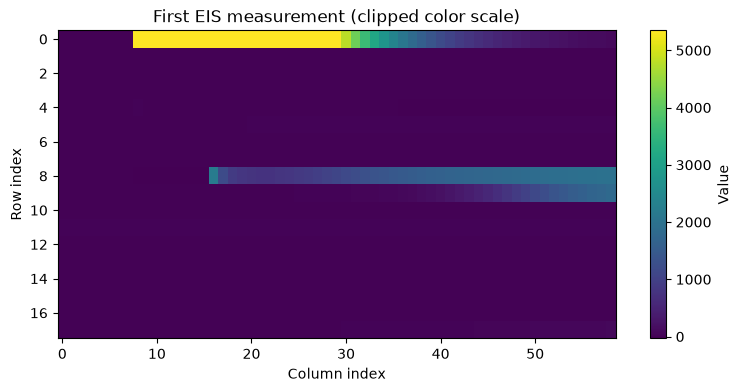

In [22]:
import numpy as np
import matplotlib.pyplot as plt

low, high = np.nanpercentile(matrix, [2, 98])
print("2nd–98th percentile:", low, high)

plt.figure(figsize=(9, 4))
plt.imshow(matrix, aspect="auto", cmap="viridis", vmin=low, vmax=high)
plt.colorbar(label="Value")
plt.xlabel("Column index")
plt.ylabel("Row index")
plt.title("First EIS measurement (clipped color scale)")
plt.show()

In [23]:
for i, row in enumerate(matrix):
    count = np.count_nonzero(row)
    if count:
        print(f"Row {i}: {count} nonzero values")
        print("  first values:", row[:12])
        print("  last values:", row[-8:])

Row 0: 51 nonzero values
  first values: [     0.          0.          0.          0.          0.          0.
      0.          0.     100019.508   87099.5859  75859.3594  66074.2031]
  last values: [263.063782 229.193222 199.552994 173.721359 151.405029 131.899292
 114.742943 100.032005]
Row 1: 51 nonzero values
  first values: [0.         0.         0.         0.         0.         0.
 0.         0.         0.17938164 0.17570229 0.17607588 0.17656714]
  last values: [0.23004805 0.23228982 0.23487242 0.23759705 0.24094181 0.24319415
 0.24736586 0.2504265 ]
Row 2: 51 nonzero values
  first values: [ 0.          0.          0.          0.          0.          0.
  0.          0.         -0.02678713 -0.02134046 -0.01678071 -0.01295965]
  last values: [0.32088485 0.36493635 0.41594437 0.4739652  0.54042876 0.61732847
 0.70574641 0.80548096]
Row 3: 51 nonzero values
  first values: [0.         0.         0.         0.         0.         0.
 0.         0.         0.18137068 0.17699353 0.176

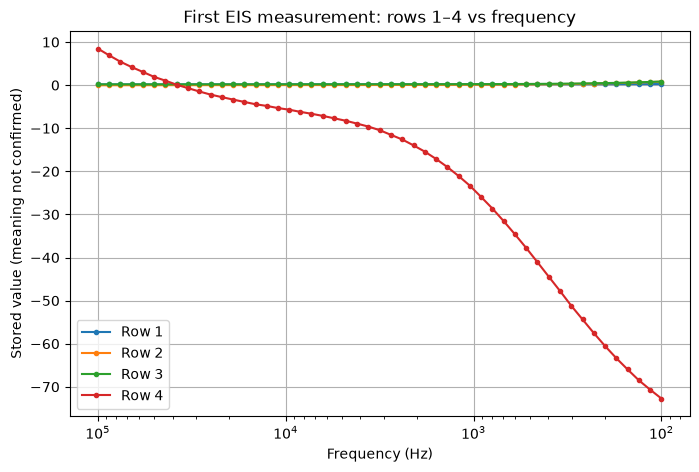

In [24]:
freq = matrix[0]
valid = freq > 0

plt.figure(figsize=(8, 5))
for i in range(1, 5):
    plt.semilogx(freq[valid], matrix[i, valid], marker=".", label=f"Row {i}")

plt.gca().invert_xaxis()
plt.xlabel("Frequency (Hz)")
plt.ylabel("Stored value (meaning not confirmed)")
plt.title("First EIS measurement: rows 1–4 vs frequency")
plt.legend()
plt.grid(True)
plt.show()

IndexError: index 4 is out of bounds for axis 0 with size 2

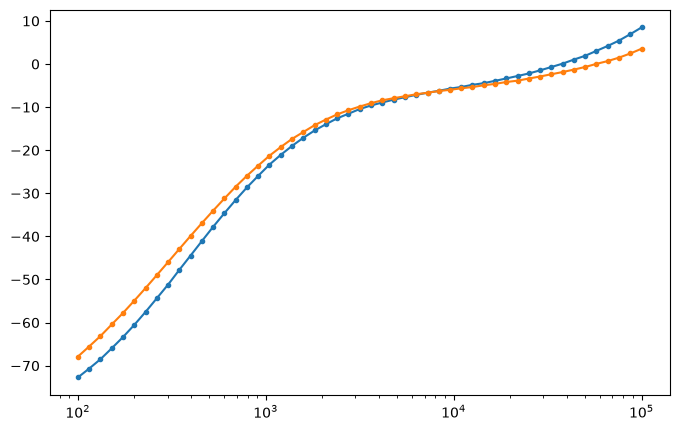

In [26]:
selected = [0, 36, 72]

with h5py.File(mat_path, "r") as f:
    data_cells = f["ES10/EIS_Data/ES10C1/EIS_Measurement/Data"]

    plt.figure(figsize=(8, 5))

    for idx in selected:
        record = f[data_cells[idx, 0]]
        spectrum = f[record[0, 0]][()]

        freq = spectrum[0]
        valid = freq > 0
        hours = float(table_df.iloc[idx]["elapsed_hours"])
        plt.semilogx(
            freq[valid],
            spectrum[4, valid],
            marker=".",
            label=f"Record {idx}, {hours:g} h",
        )

plt.gca().invert_xaxis()
plt.xlabel("Frequency (Hz)")
plt.ylabel("Stored row 4 value (units not confirmed)")
plt.title("C1 row 4 across the aging timeline")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
with h5py.File(mat_path, "r") as f:
    data_cells = f["ES10/EIS_Data/ES10C1/EIS_Measurement/Data"]

    for idx in [0, 36, 72]:
        record = f[data_cells[idx, 0]]
        spectrum = f[record[0, 0]]
        print(
            f"Record {idx}: record shape={record.shape}, "
            f"spectrum shape={spectrum.shape}, type={spectrum.dtype}"
        )

Record 0: record shape=(20, 1), spectrum shape=(18, 59), type=float64
Record 36: record shape=(5, 1), spectrum shape=(18, 59), type=float64
Record 72: record shape=(10, 1), spectrum shape=(2,), type=uint64


In [28]:
with h5py.File(mat_path, "r") as f:
    data_cells = f["ES10/EIS_Data/ES10C1/EIS_Measurement/Data"]
    record = f[data_cells[72, 0]]

    for j in range(record.shape[0]):
        item = f[record[j, 0]]
        print(f"Item {j}: shape={item.shape}, type={item.dtype}")

Item 0: shape=(2,), type=uint64
Item 1: shape=(18, 59), type=float64
Item 2: shape=(2,), type=uint64
Item 3: shape=(18, 59), type=float64
Item 4: shape=(2,), type=uint64
Item 5: shape=(18, 59), type=float64
Item 6: shape=(2,), type=uint64
Item 7: shape=(18, 59), type=float64
Item 8: shape=(2,), type=uint64
Item 9: shape=(18, 59), type=float64


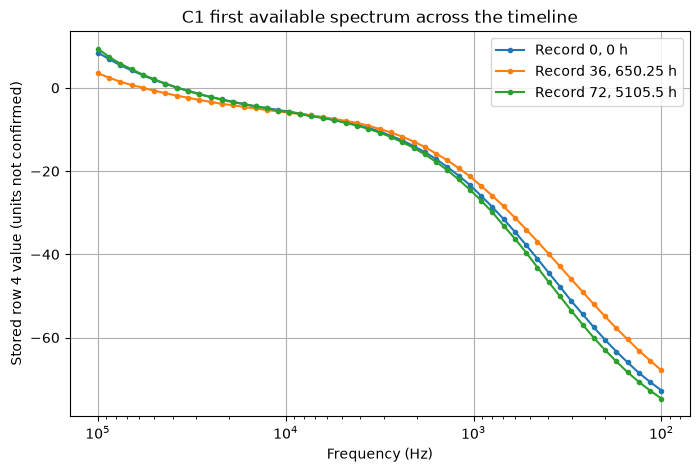

In [29]:
selected = [0, 36, 72]

with h5py.File(mat_path, "r") as f:
    data_cells = f["ES10/EIS_Data/ES10C1/EIS_Measurement/Data"]
    plt.figure(figsize=(8, 5))

    for idx in selected:
        record = f[data_cells[idx, 0]]
        spectrum = None

        for j in range(record.shape[0]):
            item = f[record[j, 0]]
            if item.dtype.kind == "f" and item.ndim == 2 and item.shape[0] == 18:
                spectrum = item[()]
                break

        if spectrum is None:
            print(f"Record {idx}: no spectrum found")
            continue

        freq = spectrum[0]
        valid = freq > 0
        hours = float(table_df.iloc[idx]["elapsed_hours"])

        plt.semilogx(
            freq[valid],
            spectrum[4, valid],
            marker=".",
            label=f"Record {idx}, {hours:g} h",
        )

plt.gca().invert_xaxis()
plt.xlabel("Frequency (Hz)")
plt.ylabel("Stored row 4 value (units not confirmed)")
plt.title("C1 first available spectrum across the timeline")
plt.legend()
plt.grid(True)
plt.show()

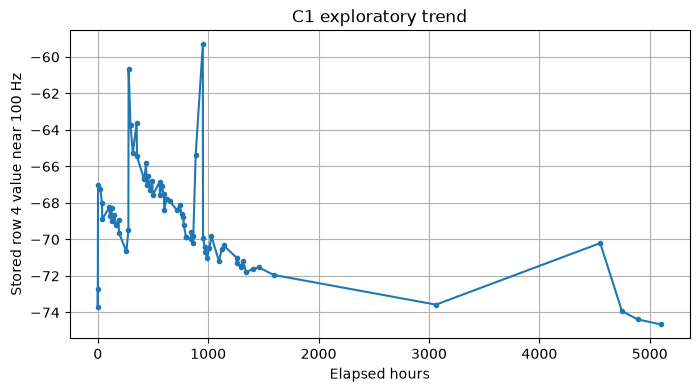

In [30]:
hours_values = []
row4_values = []

with h5py.File(mat_path, "r") as f:
    data_cells = f["ES12/EIS_Data/ES12C1/EIS_Measurement/Data"]
    for idx in range(data_cells.shape[0]):
        record = f[data_cells[idx, 0]]
        spectrum = None

        for j in range(record.shape[0]):
            item = f[record[j, 0]]
            if item.dtype.kind == "f" and item.ndim == 2 and item.shape[0] == 18:
                spectrum = item[()]
                break

        if spectrum is None:
            continue

        freq = spectrum[0]
        valid = np.flatnonzero(freq > 0)
        nearest = valid[np.argmin(np.abs(freq[valid] - 100))]

        hours_values.append(float(table_df.iloc[idx]["elapsed_hours"]))
        row4_values.append(spectrum[4, nearest])

trend_df = pd.DataFrame({
    "elapsed_hours": hours_values,
    "row4_near_100Hz": row4_values,
})

plt.figure(figsize=(8, 4))
plt.plot(trend_df["elapsed_hours"], trend_df["row4_near_100Hz"], marker=".")
plt.xlabel("Elapsed hours")
plt.ylabel("Stored row 4 value near 100 Hz")
plt.title("C1 exploratory trend")
plt.grid(True)
plt.show()

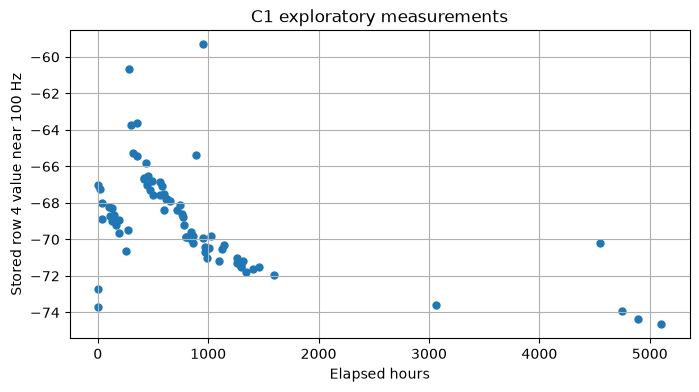

Records plotted: 73
   elapsed_hours  row4_near_100Hz
0         0.0000       -72.729370
1         0.0000       -73.681160
2         2.0000       -67.044960
3        23.0000       -67.234398
4        38.3333       -68.008629
5        40.0000       -68.896721
6       105.0000       -68.232208
7       108.0000       -68.714104
8       125.0000       -68.274422
9       128.0000       -68.990273


In [31]:
plt.figure(figsize=(8, 4))
plt.scatter(
    trend_df["elapsed_hours"],
    trend_df["row4_near_100Hz"],
    s=25,
)
plt.xlabel("Elapsed hours")
plt.ylabel("Stored row 4 value near 100 Hz")
plt.title("C1 exploratory measurements")
plt.grid(True)
plt.show()

print("Records plotted:", len(trend_df))
print(trend_df.head(10))

In [33]:
from scipy.stats import spearmanr

rho, p_value = spearmanr(
    trend_df["elapsed_hours"],
    trend_df["row4_near_100Hz"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4g}")

Spearman correlation: -0.589
P-value: 4.329e-08


C1 exploratory finding: The stored row 4 value near 100 Hz generally decreases as elapsed test time increases (Spearman ρ = −0.589, p = 4.329 × 10⁻⁸). This is an initial association from one capacitor. The row’s physical meaning and units are still unconfirmed, so this result is not yet a validated defect indicator.

In [46]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    names = f["ES12"]["EIS_Data"]["ES12C1"]["EIS_Measurement"]["ColumnNames"]
    print("Shape:", names.shape)
    print("Stored values:", names[()])

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\AppData\Local\Temp\ipykernel_31828\4280569511.py", line 2, in <module>
    names = f["ES12"]["EIS_Data"]["ES12C1"]["EIS_Measurement"]["ColumnNames"]
            ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\h5py\_hl\group.py", line 407, in __getitem__
    return self._get(name)
           ~~~~~~~~~^^^^^^
  File "h5py/_objects.pyx", line 54, in h5py._objects.with_phil.wrapper
  File "h5py/_objects.pyx", line 55, in h5py._objects.with_phil.wrapper
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\h5py\_hl\group.py", line 421, in _get
    oid = h5o.open(self.id, self._e(na

In [47]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    data = f["ES12"]["EIS_Data"]["ES12C1"]["EIS_Measurement"]["Data"]
    print("Data shape:", data.shape)

Data shape: (73, 1)


In [48]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    data = f["ES12"]["EIS_Data"]["ES12C1"]["EIS_Measurement"]["Data"]
    first_record = f[data[0, 0]]
    print("First record shape:", first_record.shape)

First record shape: (5, 1)


In [49]:
with h5py.File(data_folder / "ES12.mat", "r") as f:
    data = f["ES12"]["EIS_Data"]["ES12C1"]["EIS_Measurement"]["Data"]
    first_record = f[data[0, 0]]
    first_item = f[first_record[0, 0]]
    print("First item shape:", first_item.shape)
    print("First item values:", first_item[()])

First item shape: (18, 59)
First item values: [[  0.           0.           0.         ... 131.899292   114.742943
  100.032005  ]
 [  0.           0.           0.         ...   0.19385004   0.19724476
    0.19991165]
 [  0.           0.           0.         ...   0.60231602   0.69082183
    0.79025304]
 ...
 [  0.           0.           0.         ...   1.50442696   1.33843815
    1.18930805]
 [  0.           0.           0.         ...   1.580423     1.39192593
    1.22677267]
 [  0.           0.           0.         ...  72.1596909   74.0647964
   75.8036194 ]]


In [54]:
import mat73
import pandas as pd

es12 = mat73.loadmat(
    str(data_folder / "ES12.mat"),
    only_include="ES12/EIS_Data/EIS_Reference_Table"
)

print(es12.keys())

dict_keys(['ES12'])


In [55]:
reference_table = es12["ES12"]["EIS_Data"]["EIS_Reference_Table"]

print("Type:", type(reference_table))
print("Shape:", getattr(reference_table, "shape", None))
print("Preview:", repr(reference_table)[:1000])

TypeError: list indices must be integers or slices, not str

In [56]:
rows12 = es12["ES12"]["EIS_Data"]

table12_df = pd.DataFrame(
    [row["EIS_Reference_Table"] for row in rows12],
    columns=["date", "start_time", "end_time", "elapsed_hours"]
)

print("Table shape:", table12_df.shape)
display(table12_df.head())

Table shape: (73, 4)


,date,start_time,end_time,elapsed_hours
0,9/29/2014,,,0
1,9/30/2014,,,0
2,10/1/2014,10:00 AM,12:00 PM,2
3,10/2/2014,4:00 PM,1:00 PM,23
4,10/3/2014,4:00 PM,7:20 AM,38.3333


In [57]:
import h5py
import numpy as np
from scipy.stats import spearmanr

mat_path12 = data_folder / "ES12.mat"
values12 = []

with h5py.File(mat_path12, "r") as f:
    data_cells = f["ES12/EIS_Data/ES12C1/EIS_Measurement/Data"]

    for idx in range(data_cells.shape[0]):
        record_ref = data_cells[idx, 0]
        record = f[record_ref]
        spectrum = None

        for j in range(record.shape[0]):
            item_ref = record[j, 0]
            if not item_ref:
                continue

            item = f[item_ref]
            if (item.dtype.kind == "f" and item.ndim == 2
                    and item.shape[0] == 18):
                spectrum = item[()]
                break

        if spectrum is None:
            values12.append(np.nan)
        else:
            freq = spectrum[0]
            valid = freq > 0
            nearest = np.where(valid)[0][np.argmin(np.abs(freq[valid] - 100))]
            values12.append(spectrum[4, nearest])

if len(values12) != len(table12_df):
    print("Record count:", len(values12), "| time-table rows:", len(table12_df))
else:
    trend12 = table12_df[["elapsed_hours"]].copy()
    trend12["row4_near_100Hz"] = values12
    trend12 = trend12.dropna()

    rho12, p12 = spearmanr(
        trend12["elapsed_hours"],
        trend12["row4_near_100Hz"]
    )
    print(f"ES12 C1 Spearman correlation: {rho12:.3f}")
    print(f"P-value: {p12:.4g}")

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\AppData\Local\Temp\ipykernel_31828\2340758090.py", line 42, in <module>
    rho12, p12 = spearmanr(
                 ~~~~~~~~~^
        trend12["elapsed_hours"],
        ^^^^^^^^^^^^^^^^^^^^^^^^^
        trend12["row4_near_100Hz"]
        ^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\scipy\stats\_stats_py.py", line 5446, in spearmanr
    rs = np.corrcoef(a_ranked, rowvar=axisout)
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py", line 3029, in corrcoef
    c = cov(x, y, rowvar, dtype=dtype)
  File "C:\Users\User\burnin-latent-defect-screening\.venv\Lib\site-packa

In [58]:
x = pd.to_numeric(trend12["elapsed_hours"], errors="coerce").to_numpy(dtype=float)
y = pd.to_numeric(trend12["row4_near_100Hz"], errors="coerce").to_numpy(dtype=float)

keep = np.isfinite(x) & np.isfinite(y)
print("Valid records:", keep.sum())

rho12, p12 = spearmanr(x[keep], y[keep])
print(f"ES12 C1 Spearman correlation: {rho12:.3f}")
print(f"P-value: {p12:.4g}")

Valid records: 73
ES12 C1 Spearman correlation: -0.814
P-value: 2.129e-18


ES12 C1 exploratory finding: The stored row 4 value near 100 Hz decreases with elapsed test time (Spearman ρ = −0.814, p = 2.129 × 10⁻¹⁸). This is an initial association; row meaning and units are still unconfirmed, so it is not yet a validated defect indicator.

In [59]:
import mat73
import h5py
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

es14 = mat73.loadmat(
    str(data_folder / "ES14.mat"),
    only_include="ES14/EIS_Data/EIS_Reference_Table"
)
rows14 = es14["ES14"]["EIS_Data"]
table14_df = pd.DataFrame(
    [row["EIS_Reference_Table"] for row in rows14],
    columns=["date", "start_time", "end_time", "elapsed_hours"]
)

values14 = []

with h5py.File(data_folder / "ES14.mat", "r") as f:
    data_cells = f["ES14/EIS_Data/ES14C1/EIS_Measurement/Data"]

    for idx in range(data_cells.shape[0]):
        record_ref = data_cells[idx, 0]
        record = f[record_ref]
        spectrum = None

        for j in range(record.shape[0]):
            item_ref = record[j, 0]
            if not item_ref:
                continue

            item = f[item_ref]
            if item.dtype.kind == "f" and item.ndim == 2 and item.shape[0] == 18:
                spectrum = item[()]
                break

        if spectrum is None:
            values14.append(np.nan)
        else:
            freq = spectrum[0]
            valid = freq > 0
            nearest = np.where(valid)[0][np.argmin(np.abs(freq[valid] - 100))]
            values14.append(spectrum[4, nearest])

if len(values14) != len(table14_df):
    print("Record count:", len(values14), "| time-table rows:", len(table14_df))
else:
    trend14 = table14_df[["elapsed_hours"]].copy()
    trend14["row4_near_100Hz"] = values14

    x = pd.to_numeric(trend14["elapsed_hours"], errors="coerce").to_numpy(dtype=float)
    y = pd.to_numeric(trend14["row4_near_100Hz"], errors="coerce").to_numpy(dtype=float)
    keep = np.isfinite(x) & np.isfinite(y)

    rho14, p14 = spearmanr(x[keep], y[keep])
    print("Valid records:", keep.sum())
    print(f"ES14 C1 Spearman correlation: {rho14:.3f}")
    print(f"P-value: {p14:.4g}")

Valid records: 73
ES14 C1 Spearman correlation: -0.805
P-value: 1.004e-17


ES14 C1 exploratory finding: The stored row 4 value near 100 Hz decreases with elapsed test time (Spearman ρ = −0.805, p = 1.004 × 10⁻¹⁷). This is an initial association; row meaning and units remain unconfirmed.

In [60]:
comparison = pd.DataFrame({
    "Dataset": ["ES10 (10 V)", "ES12 (12 V)", "ES14 (14 V)"],
    "Spearman rho": [rho, rho12, rho14],
    "p-value": [p_value, p12, p14],
})

display(comparison)

,Dataset,Spearman rho,p-value
0,ES10 (10 V),-0.588614,4.328898e-08
1,ES12 (12 V),-0.813764,2.129170e-18
2,ES14 (14 V),-0.804508,1.004405e-17


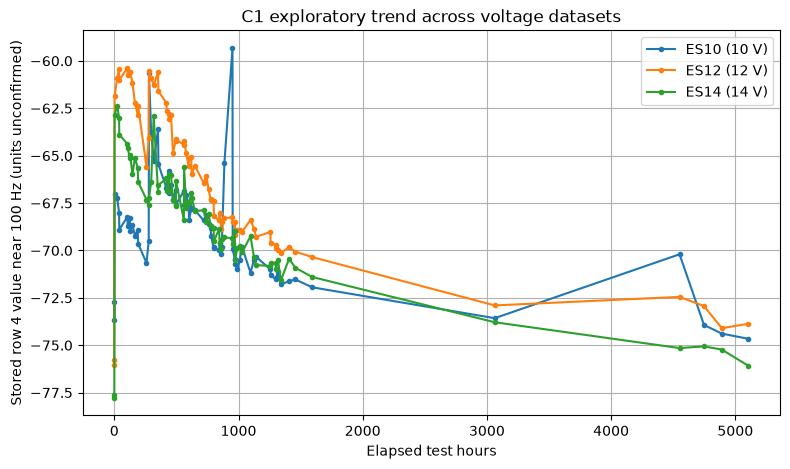

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for trend, label in [
    (trend_df, "ES10 (10 V)"),
    (trend12, "ES12 (12 V)"),
    (trend14, "ES14 (14 V)"),
]:
    x = pd.to_numeric(trend["elapsed_hours"], errors="coerce")
    y = pd.to_numeric(trend["row4_near_100Hz"], errors="coerce")
    valid = x.notna() & y.notna()
    plt.plot(x[valid], y[valid], marker=".", label=label)

plt.xlabel("Elapsed test hours")
plt.ylabel("Stored row 4 value near 100 Hz (units unconfirmed)")
plt.title("C1 exploratory trend across voltage datasets")
plt.legend()
plt.grid(True)
plt.show()

C1 comparison: The stored row 4 value near 100 Hz generally decreases over elapsed test time in the 10 V, 12 V, and 14 V datasets. The trend is noisy, especially early in testing, and late measurements are sparse. This is exploratory: the row’s physical meaning and units are unconfirmed, and the plot alone does not show that voltage causes the change.

In [62]:
with h5py.File(data_folder / "ES10.mat", "r") as f:
    for c in range(1, 9):
        path = f"ES10/EIS_Data/ES10C{c}/EIS_Measurement/Data"
        print(f"C{c}: {f[path].shape[0]} records")

C1: 73 records
C2: 73 records
C3: 73 records
C4: 73 records
C5: 73 records
C6: 73 records
C7: 73 records
C8: 73 records


In [63]:
from scipy.stats import spearmanr

hours = pd.to_numeric(
    table_df["elapsed_hours"], errors="coerce"
).to_numpy(dtype=float)

results = []

with h5py.File(data_folder / "ES10.mat", "r") as f:
    for c in range(1, 9):
        path = f"ES10/EIS_Data/ES10C{c}/EIS_Measurement/Data"
        data_cells = f[path]
        values = []

        for idx in range(data_cells.shape[0]):
            record_ref = data_cells[idx, 0]
            record = f[record_ref]
            spectrum = None

            for j in range(record.shape[0]):
                item_ref = record[j, 0]
                if not item_ref:
                    continue

                item = f[item_ref]
                if item.dtype.kind == "f" and item.ndim == 2 and item.shape[0] == 18:
                    spectrum = item[()]
                    break

            if spectrum is None:
                values.append(np.nan)
            else:
                freq = spectrum[0]
                valid_freq = freq > 0
                nearest = np.where(valid_freq)[0][
                    np.argmin(np.abs(freq[valid_freq] - 100))
                ]
                values.append(spectrum[4, nearest])

        y = np.asarray(values, dtype=float)
        keep = np.isfinite(hours) & np.isfinite(y)
        rho, p = spearmanr(hours[keep], y[keep])

        results.append({
            "Capacitor": f"C{c}",
            "Valid records": int(keep.sum()),
            "Spearman rho": rho,
            "p-value": p,
        })

display(pd.DataFrame(results).round(4))

,Capacitor,Valid records,Spearman rho,p-value
0,C1,73,-0.5886,0.0
1,C2,73,-0.8080,0.0
2,C3,73,-0.7992,0.0
3,C4,73,-0.7861,0.0
4,C5,73,-0.8138,0.0
5,C6,73,-0.7857,0.0
6,C7,73,-0.7822,0.0
7,C8,73,-0.5445,0.0


ES10 channel comparison: All eight capacitors show a downward association between the stored row 4 value near 100 Hz and elapsed test time (Spearman ρ ranges from −0.5445 to −0.8138; 73 records per capacitor). The association is weaker for C8. This remains exploratory because row 4’s physical meaning and units are unconfirmed.

In [64]:
from scipy.stats import spearmanr

hours = pd.to_numeric(
    table12_df["elapsed_hours"], errors="coerce"
).to_numpy(dtype=float)

with h5py.File(data_folder / "ES12.mat", "r") as f:
    for c in range(1, 9):
        path = f"ES12/EIS_Data/ES12C{c}/EIS_Measurement/Data"
        data_cells = f[path]
        values = []

        for idx in range(data_cells.shape[0]):
            record_ref = data_cells[idx, 0]
            record = f[record_ref]
            spectrum = None

            for j in range(record.shape[0]):
                item_ref = record[j, 0]
                if not item_ref:
                    continue

                item = f[item_ref]
                if item.dtype.kind == "f" and item.ndim == 2 and item.shape[0] == 18:
                    spectrum = item[()]
                    break

            if spectrum is None:
                values.append(np.nan)
            else:
                freq = spectrum[0]
                valid_freq = freq > 0
                nearest = np.where(valid_freq)[0][
                    np.argmin(np.abs(freq[valid_freq] - 100))
                ]
                values.append(spectrum[4, nearest])

        y = np.asarray(values, dtype=float)
        keep = np.isfinite(hours) & np.isfinite(y)
        rho, p = spearmanr(hours[keep], y[keep])

        results.append({
            "Capacitor": f"C{c}",
            "Valid records": int(keep.sum()),
            "Spearman rho": rho,
            "p-value": p,
        })

display(pd.DataFrame(results).round(4))

,Capacitor,Valid records,Spearman rho,p-value
0,C1,73,-0.5886,0.0
1,C2,73,-0.8080,0.0
2,C3,73,-0.7992,0.0
3,C4,73,-0.7861,0.0
4,C5,73,-0.8138,0.0
5,C6,73,-0.7857,0.0
6,C7,73,-0.7822,0.0
7,C8,73,-0.5445,0.0
8,C1,73,-0.8138,0.0
9,C2,73,-0.8118,0.0


In [65]:
from scipy.stats import spearmanr

hours = pd.to_numeric(
    table14_df["elapsed_hours"], errors="coerce"
).to_numpy(dtype=float)

with h5py.File(data_folder / "ES14.mat", "r") as f:
    for c in range(1, 9):
        path = f"ES14/EIS_Data/ES14C{c}/EIS_Measurement/Data"
        data_cells = f[path]
        values = []

        for idx in range(data_cells.shape[0]):
            record_ref = data_cells[idx, 0]
            record = f[record_ref]
            spectrum = None

            for j in range(record.shape[0]):
                item_ref = record[j, 0]
                if not item_ref:
                    continue

                item = f[item_ref]
                if item.dtype.kind == "f" and item.ndim == 2 and item.shape[0] == 18:
                    spectrum = item[()]
                    break

            if spectrum is None:
                values.append(np.nan)
            else:
                freq = spectrum[0]
                valid_freq = freq > 0
                nearest = np.where(valid_freq)[0][
                    np.argmin(np.abs(freq[valid_freq] - 100))
                ]
                values.append(spectrum[4, nearest])

        y = np.asarray(values, dtype=float)
        keep = np.isfinite(hours) & np.isfinite(y)
        rho, p = spearmanr(hours[keep], y[keep])

        results.append({
            "Capacitor": f"C{c}",
            "Valid records": int(keep.sum()),
            "Spearman rho": rho,
            "p-value": p,
        })

display(pd.DataFrame(results).round(4))

,Capacitor,Valid records,Spearman rho,p-value
0,C1,73,-0.5886,0.0
1,C2,73,-0.8080,0.0
2,C3,73,-0.7992,0.0
3,C4,73,-0.7861,0.0
4,C5,73,-0.8138,0.0
5,C6,73,-0.7857,0.0
6,C7,73,-0.7822,0.0
7,C8,73,-0.5445,0.0
8,C1,73,-0.8138,0.0
9,C2,73,-0.8118,0.0


In [66]:
results_df = pd.DataFrame(results)
results_df["Voltage"] = np.repeat(["10 V", "12 V", "14 V"], 8)

rho_table = results_df.pivot(
    index="Capacitor",
    columns="Voltage",
    values="Spearman rho"
)

display(rho_table.round(3))

Voltage,10 V,12 V,14 V
Capacitor,,,
C1,-0.589,-0.814,-0.805
C2,-0.808,-0.812,-0.816
C3,-0.799,-0.815,-0.803
C4,-0.786,-0.816,-0.784
C5,-0.814,-0.823,-0.806
C6,-0.786,-0.820,-0.817
C7,-0.782,-0.800,-0.808
C8,-0.544,-0.811,-0.806


Voltage comparison: The stored row 4 value near 100 Hz decreases with elapsed test time for all eight capacitors in the 10 V, 12 V, and 14 V datasets. The pattern is more consistent at 12 V and 14 V; C1 and C8 show weaker associations at 10 V. These are exploratory correlations from repeated measurements. The row’s physical meaning and units remain unconfirmed, and the results do not establish that voltage causes the change or that this value identifies defects.

Label limitation: This analysis tracks measurement changes over test time. The data used here does not provide a confirmed defective-versus-good label for each capacitor, so we cannot calculate defect-detection performance or validate a screening threshold.